# **Experiment-7: Text Classification using Deep Learning Models**

## **Experiment 7.1:** Implement sentiment analysis using Logistic regression,  LSTM, and Vanilla Transformer models and BERT pretrained model on IMDB Movie Reviews Dataset and perform comparative analysis among all the models.

```
Dataset and Sample code: https://github.com/Ankit152/IMDB-sentiment-analysis/tree/master

https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
```

## (Evaluate using F1, Precision, Recall, and analyse with Confusion Matrix)

In [1]:
!pip install -q transformers datasets accelerate

## 1. Import Libraries


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense, Dropout,
    GlobalAveragePooling1D, MultiHeadAttention, LayerNormalization
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Upload and Load Dataset


In [3]:
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())
print("\nClass distribution:")
print(df["sentiment"].value_counts())

Saving IMDB Dataset.csv to IMDB Dataset (1).csv
Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Class distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


## 3. Data Preprocessing


In [4]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(clean_text)
df["label"] = df["sentiment"].map({"negative": 0, "positive": 1})

display(df[["review", "clean_review", "sentiment", "label"]].head())

,review,clean_review,sentiment,label
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...,positive,1
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...,positive,1


## 4. Exploratory Data Analysis


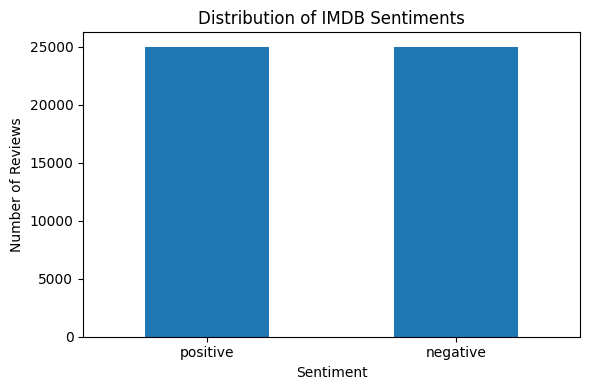

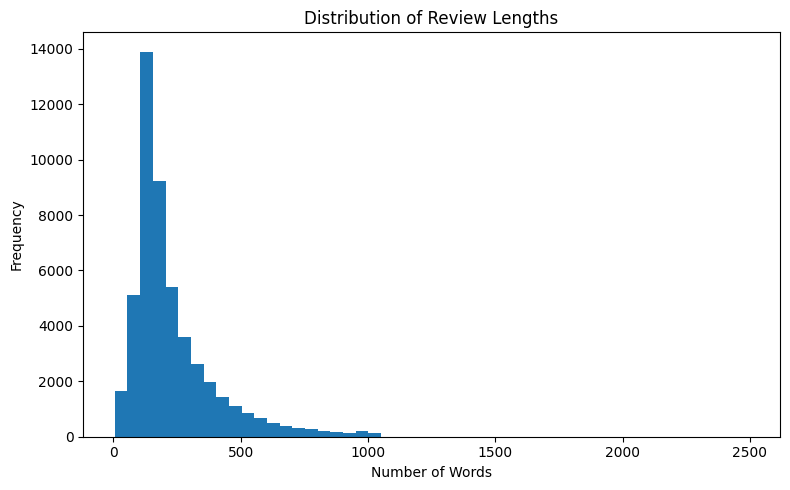

,review_length
count,50000.000000
mean,234.162560
std,173.504852
min,6.000000
25%,128.000000
50%,176.000000
75%,284.000000
max,2494.000000


In [5]:
plt.figure(figsize=(6, 4))
df["sentiment"].value_counts().plot(kind="bar")
plt.title("Distribution of IMDB Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

df["review_length"] = df["clean_review"].apply(lambda x: len(x.split()))

plt.figure(figsize=(8, 5))
plt.hist(df["review_length"], bins=50)
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

display(df["review_length"].describe())

## 5. Train-Test Split


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"],
    df["label"],
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 40000
Testing samples: 10000


# Model 1: Logistic Regression


LOGISTIC REGRESSION RESULTS
Accuracy : 0.9027
Precision: 0.8956573000589507
Recall   : 0.9116
F1 Score : 0.9035583308553871

               precision    recall  f1-score   support

           0       0.91      0.89      0.90      5000
           1       0.90      0.91      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



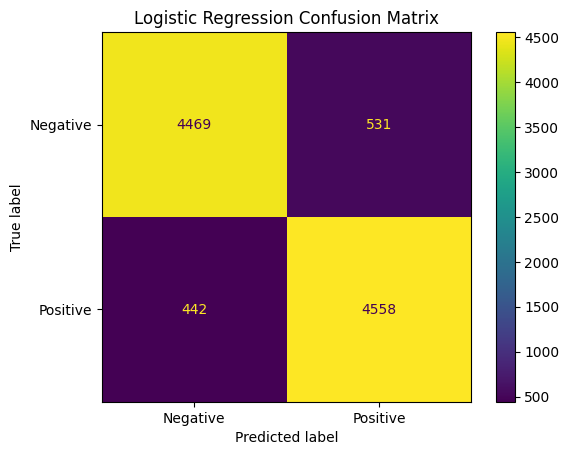

In [7]:
tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print("LOGISTIC REGRESSION RESULTS")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)
print("\n", classification_report(y_test, lr_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred, display_labels=["Negative", "Positive"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

# Model 2: LSTM


In [8]:
MAX_WORDS = 30000
MAX_LEN = 300

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_sequences, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    test_sequences, maxlen=MAX_LEN, padding="post", truncating="post"
)

lstm_model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=128),
    LSTM(64),
    Dropout(0.5),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [9]:
history_lstm = lstm_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=5,
    batch_size=128
)

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.5058 - loss: 0.6935 - val_accuracy: 0.5151 - val_loss: 0.6918
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.5344 - loss: 0.6837 - val_accuracy: 0.5699 - val_loss: 0.6582
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.5694 - loss: 0.6456 - val_accuracy: 0.5303 - val_loss: 0.6824
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.5882 - loss: 0.6041 - val_accuracy: 0.5624 - val_loss: 0.6772
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.6287 - loss: 0.5577 - val_accuracy: 0.7961 - val_loss: 0.5633


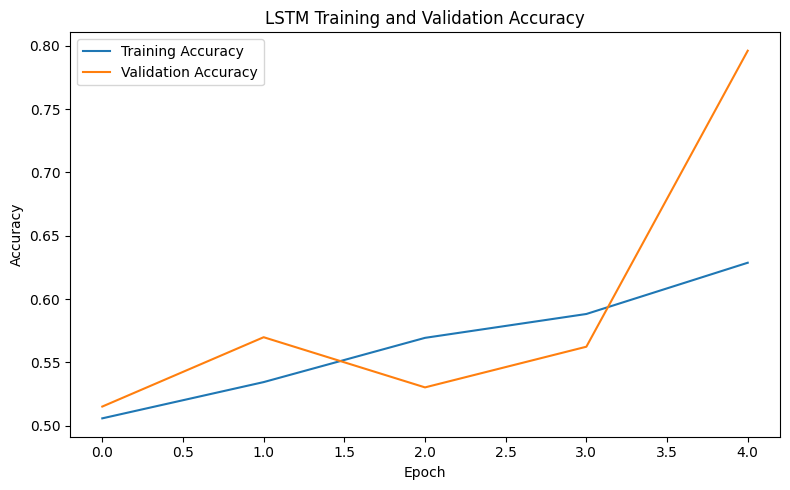

LSTM RESULTS
Accuracy : 0.7948
Precision: 0.7848859683030537
Recall   : 0.8122
F1 Score : 0.7983094161588362

               precision    recall  f1-score   support

           0       0.81      0.78      0.79      5000
           1       0.78      0.81      0.80      5000

    accuracy                           0.79     10000
   macro avg       0.80      0.79      0.79     10000
weighted avg       0.80      0.79      0.79     10000



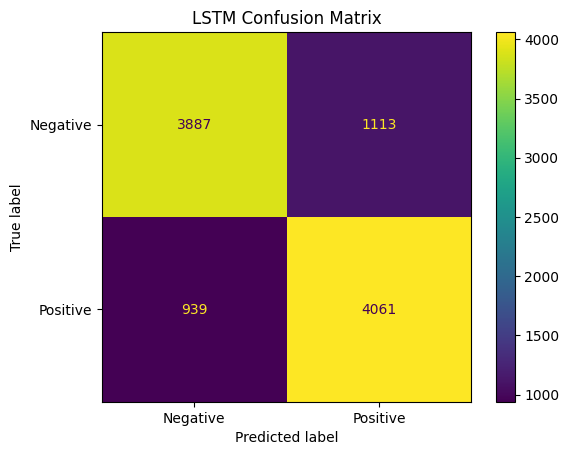

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(history_lstm.history["accuracy"], label="Training Accuracy")
plt.plot(history_lstm.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

lstm_prob = lstm_model.predict(X_test_pad, verbose=0).flatten()
lstm_pred = (lstm_prob >= 0.5).astype(int)

lstm_accuracy = accuracy_score(y_test, lstm_pred)
lstm_precision = precision_score(y_test, lstm_pred)
lstm_recall = recall_score(y_test, lstm_pred)
lstm_f1 = f1_score(y_test, lstm_pred)

print("LSTM RESULTS")
print("Accuracy :", lstm_accuracy)
print("Precision:", lstm_precision)
print("Recall   :", lstm_recall)
print("F1 Score :", lstm_f1)
print("\n", classification_report(y_test, lstm_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, lstm_pred, display_labels=["Negative", "Positive"]
)
plt.title("LSTM Confusion Matrix")
plt.show()

# Model 3: Vanilla Transformer


In [11]:
class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super().__init__()
        self.att = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = Sequential([
            Dense(ff_dim, activation="relu"),
            Dense(embed_dim)
        ])
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(rate)
        self.dropout2 = Dropout(rate)

    def call(self, inputs, training=False):
        attention_output = self.att(inputs, inputs)
        attention_output = self.dropout1(attention_output, training=training)
        out1 = self.layernorm1(inputs + attention_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)


class TokenAndPositionEmbedding(tf.keras.layers.Layer):
    def __init__(self, maxlen, vocab_size, embed_dim):
        super().__init__()
        self.token_emb = Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = Embedding(input_dim=maxlen, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        positions = self.pos_emb(positions)
        x = self.token_emb(x)
        return x + positions

In [12]:
embed_dim = 64
num_heads = 2
ff_dim = 128

inputs = Input(shape=(MAX_LEN,))
embedding_layer = TokenAndPositionEmbedding(MAX_LEN, MAX_WORDS, embed_dim)
x = embedding_layer(inputs)

transformer_block = TransformerBlock(embed_dim, num_heads, ff_dim)
x = transformer_block(x)

x = GlobalAveragePooling1D()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)
outputs = Dense(1, activation="sigmoid")(x)

transformer_model = Model(inputs=inputs, outputs=outputs)

transformer_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

transformer_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_and_position_embedding    │ (None, 300, 64)        │     1,939,200 │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 300, 64)        │        50,048 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,993,473 (7.60 MB)

 Trainable params: 1,993,473 (7.60 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history_transformer = transformer_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=5,
    batch_size=128
)

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.7371 - loss: 0.4873 - val_accuracy: 0.8781 - val_loss: 0.2884
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.9124 - loss: 0.2282 - val_accuracy: 0.8838 - val_loss: 0.2913
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.9473 - loss: 0.1471 - val_accuracy: 0.8899 - val_loss: 0.2957
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.9713 - loss: 0.0890 - val_accuracy: 0.8826 - val_loss: 0.3655
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.9812 - loss: 0.0597 - val_accuracy: 0.8796 - val_loss: 0.4549


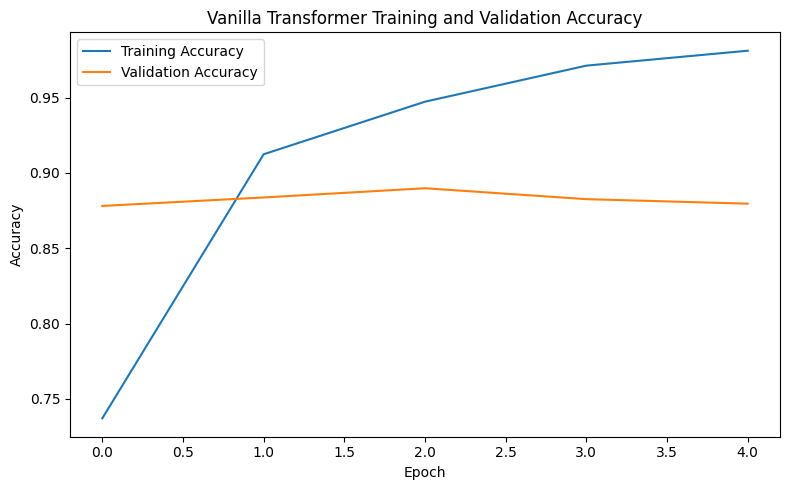

VANILLA TRANSFORMER RESULTS
Accuracy : 0.8771
Precision: 0.8927306811081025
Recall   : 0.8572
F1 Score : 0.8746046321803898

               precision    recall  f1-score   support

           0       0.86      0.90      0.88      5000
           1       0.89      0.86      0.87      5000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



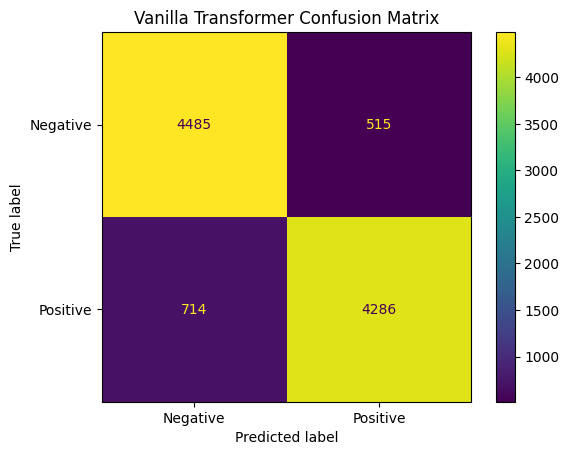

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(history_transformer.history["accuracy"], label="Training Accuracy")
plt.plot(history_transformer.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Vanilla Transformer Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

transformer_prob = transformer_model.predict(X_test_pad, verbose=0).flatten()
transformer_pred = (transformer_prob >= 0.5).astype(int)

trans_accuracy = accuracy_score(y_test, transformer_pred)
trans_precision = precision_score(y_test, transformer_pred)
trans_recall = recall_score(y_test, transformer_pred)
trans_f1 = f1_score(y_test, transformer_pred)

print("VANILLA TRANSFORMER RESULTS")
print("Accuracy :", trans_accuracy)
print("Precision:", trans_precision)
print("Recall   :", trans_recall)
print("F1 Score :", trans_f1)
print("\n", classification_report(y_test, transformer_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, transformer_pred, display_labels=["Negative", "Positive"]
)
plt.title("Vanilla Transformer Confusion Matrix")
plt.show()

# Model 4: Pretrained BERT

> **Recommended:** In Google Colab, select **Runtime → Change runtime type → T4 GPU** before training BERT.


In [15]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from datasets import Dataset

bert_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

train_df = pd.DataFrame({
    "text": X_train.values,
    "label": y_train.values
})

test_df = pd.DataFrame({
    "text": X_test.values,
    "label": y_test.values
})

train_dataset = Dataset.from_pandas(train_df, preserve_index=False)
test_dataset = Dataset.from_pandas(test_df, preserve_index=False)

def bert_tokenize(batch):
    return bert_tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=256
    )

train_dataset = train_dataset.map(bert_tokenize, batched=True)
test_dataset = test_dataset.map(bert_tokenize, batched=True)

train_dataset = train_dataset.remove_columns(["text"])
test_dataset = test_dataset.remove_columns(["text"])

train_dataset.set_format("torch")
test_dataset.set_format("torch")

bert_model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/40000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [16]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions),
        "recall": recall_score(labels, predictions),
        "f1": f1_score(labels, predictions)
    }

training_args = TrainingArguments(
    output_dir="./bert_results",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=100,
    report_to="none",
    load_best_model_at_end=True
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.227954,0.204196,0.925200,0.916373,0.935800,0.925985
2,0.144717,0.250218,0.930900,0.925538,0.937200,0.931333


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=5000, training_loss=0.19773308582305907, metrics={'train_runtime': 3684.7064, 'train_samples_per_second': 21.711, 'train_steps_per_second': 1.357, 'total_flos': 1.05244422144e+16, 'train_loss': 0.19773308582305907, 'epoch': 2.0})

BERT RESULTS
Accuracy : 0.9253
Precision: 0.9165523996082272
Recall   : 0.9358
F1 Score : 0.9260761999010391

               precision    recall  f1-score   support

    Negative       0.93      0.91      0.92      5000
    Positive       0.92      0.94      0.93      5000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



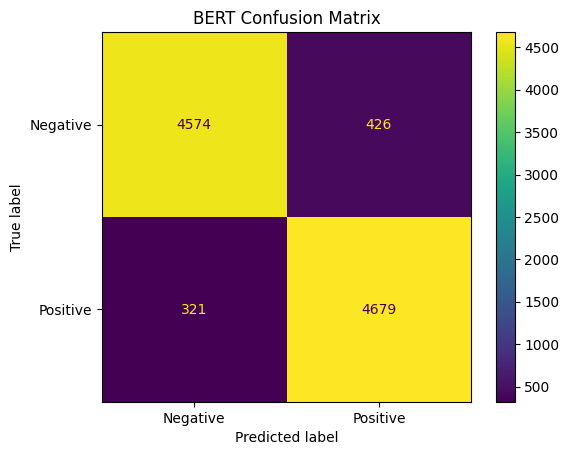

In [17]:
bert_output = trainer.predict(test_dataset)
bert_pred = np.argmax(bert_output.predictions, axis=1)

bert_accuracy = accuracy_score(y_test, bert_pred)
bert_precision = precision_score(y_test, bert_pred)
bert_recall = recall_score(y_test, bert_pred)
bert_f1 = f1_score(y_test, bert_pred)

print("BERT RESULTS")
print("Accuracy :", bert_accuracy)
print("Precision:", bert_precision)
print("Recall   :", bert_recall)
print("F1 Score :", bert_f1)
print("\n", classification_report(
    y_test, bert_pred, target_names=["Negative", "Positive"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test, bert_pred, display_labels=["Negative", "Positive"]
)
plt.title("BERT Confusion Matrix")
plt.show()

# Comparative Analysis


In [18]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "LSTM",
        "Vanilla Transformer",
        "BERT"
    ],
    "Accuracy": [
        lr_accuracy,
        lstm_accuracy,
        trans_accuracy,
        bert_accuracy
    ],
    "Precision": [
        lr_precision,
        lstm_precision,
        trans_precision,
        bert_precision
    ],
    "Recall": [
        lr_recall,
        lstm_recall,
        trans_recall,
        bert_recall
    ],
    "F1 Score": [
        lr_f1,
        lstm_f1,
        trans_f1,
        bert_f1
    ]
})

results = results.round(4)
display(results)

print("\nBest model by F1 Score:")
display(results.loc[[results["F1 Score"].idxmax()]])

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9027,0.8957,0.9116,0.9036
1,LSTM,0.7948,0.7849,0.8122,0.7983
2,Vanilla Transformer,0.8771,0.8927,0.8572,0.8746
3,BERT,0.9253,0.9166,0.9358,0.9261



Best model by F1 Score:


,Model,Accuracy,Precision,Recall,F1 Score
3,BERT,0.9253,0.9166,0.9358,0.9261


## Performance Comparison Graph


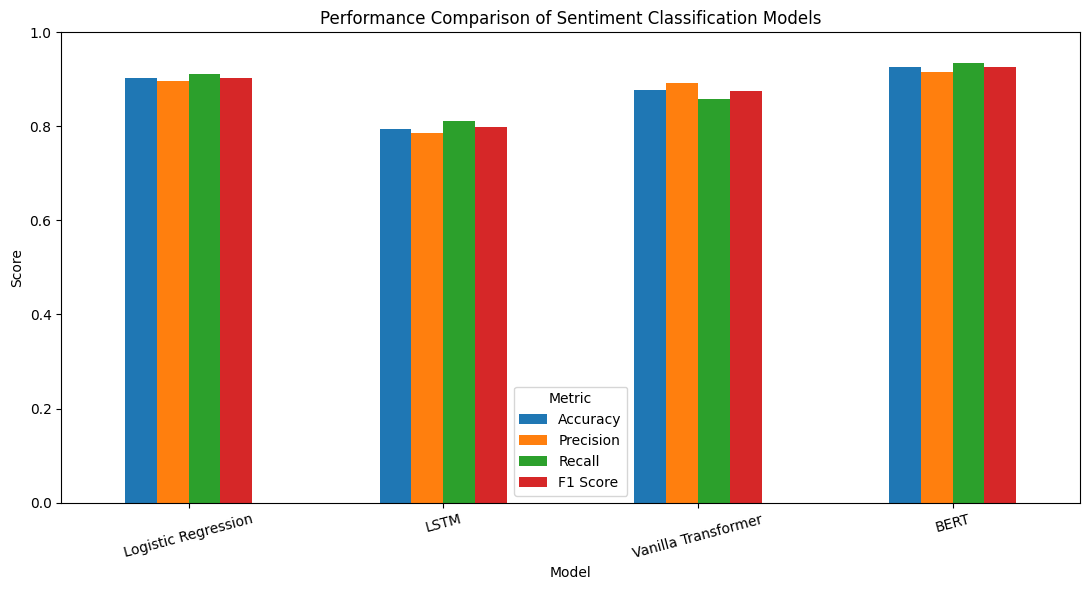

In [19]:
results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Sentiment Classification Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

## Confusion Matrices of All Models


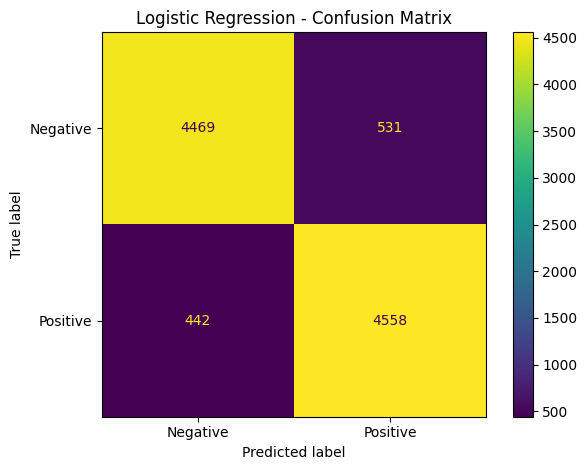

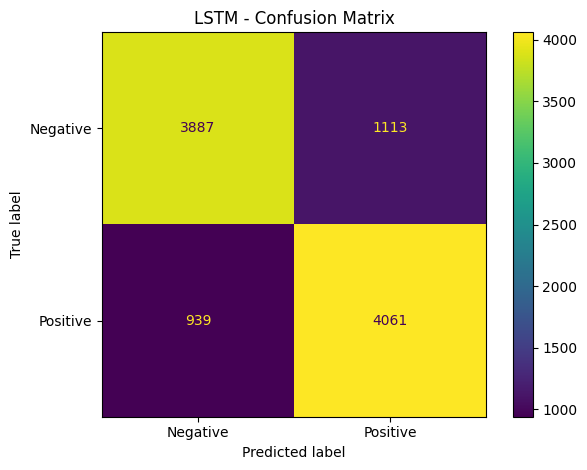

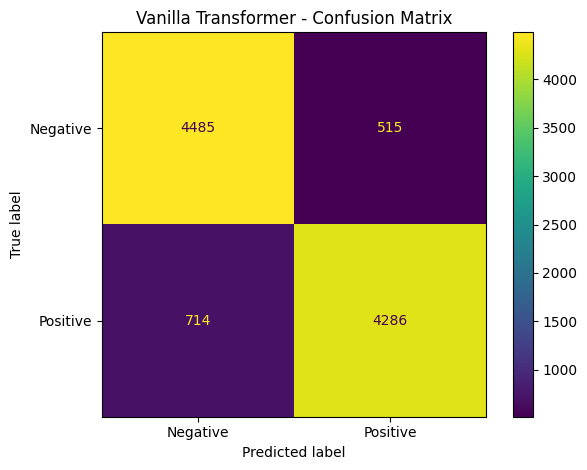

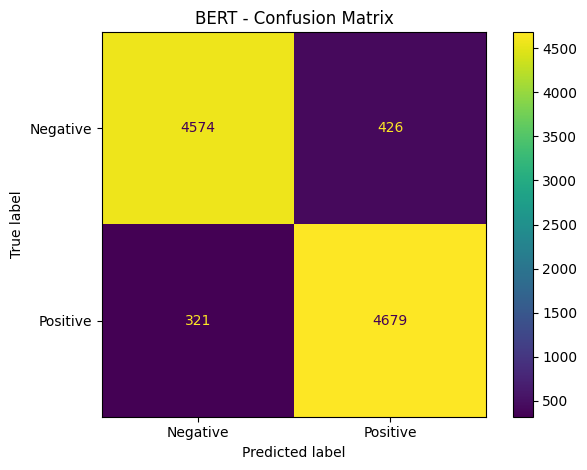

In [20]:
models_predictions = {
    "Logistic Regression": lr_pred,
    "LSTM": lstm_pred,
    "Vanilla Transformer": transformer_pred,
    "BERT": bert_pred
}

for model_name, prediction in models_predictions.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediction,
        display_labels=["Negative", "Positive"]
    )
    plt.title(f"{model_name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

## Result

Sentiment analysis was implemented using Logistic Regression, LSTM, Vanilla Transformer, and pretrained BERT. The models were evaluated using Accuracy, Precision, Recall, F1-score, and Confusion Matrices. The final comparison table reports the values obtained from the actual execution of the models.

## Conclusion

This experiment demonstrates traditional machine learning, recurrent neural networks, self-attention-based Transformer models, and pretrained language models for sentiment classification. Logistic Regression provides a strong TF-IDF baseline, LSTM learns sequential relationships, the Vanilla Transformer models contextual relationships through self-attention, and BERT benefits from large-scale language-model pretraining before fine-tuning on the IMDB sentiment classification task.
